#Loading the data

In [6]:
import pandas as pd

file_path = "E:\\RetailPulse\\data\\raw\\online_retail_II.xlsx"

df_2009_2010 = pd.read_excel(
    file_path,
    sheet_name="Year 2009-2010"
)

df_2010_2011 = pd.read_excel(
    file_path,
    sheet_name="Year 2010-2011"
)

print("2009-2010:", df_2009_2010.shape)
print("2010-2011:", df_2010_2011.shape)

2009-2010: (525461, 8)
2010-2011: (541910, 8)


#Concatinating the data

In [7]:
df = pd.concat([df_2009_2010, df_2010_2011], ignore_index=True)
print("combined dataset:", df.shape)

combined dataset: (1067371, 8)


#Inspecting the data

In [8]:
df_raw = df.copy()

In [9]:
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [10]:
df.tail()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
1067366,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
1067367,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
1067368,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France
1067369,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France
1067370,581587,POST,POSTAGE,1,2011-12-09 12:50:00,18.00,12680.0,France


In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[us]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 78.8+ MB


In [12]:
df.describe()

,Quantity,InvoiceDate,Price,Customer ID
count,1.067371e+06,1067371,1.067371e+06,824364.000000
mean,9.938898e+00,2011-01-02 21:13:55.394029,4.649388e+00,15324.638504
min,-8.099500e+04,2009-12-01 07:45:00,-5.359436e+04,12346.000000
25%,1.000000e+00,2010-07-09 09:46:00,1.250000e+00,13975.000000
50%,3.000000e+00,2010-12-07 15:28:00,2.100000e+00,15255.000000
75%,1.000000e+01,2011-07-22 10:23:00,4.150000e+00,16797.000000
max,8.099500e+04,2011-12-09 12:50:00,3.897000e+04,18287.000000
std,1.727058e+02,NaN,1.235531e+02,1697.464450


In [13]:
df.columns.tolist()

['Invoice',
 'StockCode',
 'Description',
 'Quantity',
 'InvoiceDate',
 'Price',
 'Customer ID',
 'Country']

In [14]:
missing_values = df.isnull().sum()
missing_percentage = (df.isnull().mean() * 100).round(2)

missing_report = pd.DataFrame(
    {
        "Missing Values": missing_values,
        "Missing Percentage": missing_percentage
    }
)

missing_report.sort_values("Missing Percentage", ascending=False)

,Missing Values,Missing Percentage
Customer ID,243007,22.77
Description,4382,0.41
StockCode,0,0.00
Invoice,0,0.00
Quantity,0,0.00
InvoiceDate,0,0.00
Price,0,0.00
Country,0,0.00


In [15]:
duplicated_count = df.duplicated().sum()
duplicated_percentage = (duplicated_count / len(df) * 100).round(2)

print(f"duplicate count: {duplicated_count}")
print(f"duplicate percentage: {duplicated_percentage}%")

duplicate count: 34335
duplicate percentage: 3.22%


In [16]:
df["Invoice"].astype(str).str.startswith("C").sum()

df["is_cancelled"] = df["Invoice"].astype(str).str.startswith("C")

df["is_cancelled"].value_counts()

is_cancelled
False    1047877
True       19494
Name: count, dtype: int64

In [17]:
df.groupby("is_cancelled")["Quantity"].agg(
    ["count", "min", "max", "mean"]
)

,count,min,max,mean
is_cancelled,,,,
False,1047877,-9600,80995,10.592354
True,19494,-80995,1,-25.186827


In [18]:
negative_quantity = df["Quantity"] < 0

print("Negative quantity records:", negative_quantity.sum())

print("Percentage:", round(negative_quantity.mean() * 100, 2))



Negative quantity records: 22950
Percentage: 2.15


In [19]:
# Check negative quantities in cancelled vs non-cancelled invoices

pd.crosstab(
    df["is_cancelled"],
    df["Quantity"] < 0,
    margins=True
)

Quantity,False,True,All
is_cancelled,,,
False,1044420,3457,1047877
True,1,19493,19494
All,1044421,22950,1067371


In [20]:
print("zero price records", (df["Price"] == 0).sum())
print("negative price records", (df["Price"] < 0).sum())

zero price records 6202
negative price records 5


In [21]:
df["Price"].describe()

count    1.067371e+06
mean     4.649388e+00
std      1.235531e+02
min     -5.359436e+04
25%      1.250000e+00
50%      2.100000e+00
75%      4.150000e+00
max      3.897000e+04
Name: Price, dtype: float64

In [22]:
df["revenue"] = df["Quantity"] * df["Price"]
df["revenue"].head()


0     83.4
1     81.0
2     81.0
3    100.8
4     30.0
Name: revenue, dtype: float64

In [23]:
df["revenue"].describe()

count    1.067371e+06
mean     1.806987e+01
std      2.924202e+02
min     -1.684696e+05
25%      3.750000e+00
50%      9.900000e+00
75%      1.770000e+01
max      1.684696e+05
Name: revenue, dtype: float64

In [24]:
print("Minimum date:", df["InvoiceDate"].min())
print("Maximum date:", df["InvoiceDate"].max())

Minimum date: 2009-12-01 07:45:00
Maximum date: 2011-12-09 12:50:00


In [25]:
df["InvoiceDate"].describe()

count                       1067371
mean     2011-01-02 21:13:55.394029
min             2009-12-01 07:45:00
25%             2010-07-09 09:46:00
50%             2010-12-07 15:28:00
75%             2011-07-22 10:23:00
max             2011-12-09 12:50:00
Name: InvoiceDate, dtype: object

In [26]:
print("Total transactions:", len(df))

print("Unique invoices:", df["Invoice"].nunique())

print("Unique products:",df["StockCode"].nunique())

print("Unique customers:",df["Customer ID"].nunique())

print("Unique countries:",df["Country"].nunique())

Total transactions: 1067371


Unique invoices: 53628
Unique products: 5305
Unique customers: 5942
Unique countries: 43


In [27]:
country_sales = df.groupby("Country")["revenue"].sum().sort_values(ascending=False)
country_sales.head(10)

Country
United Kingdom    1.638258e+07
EIRE              6.155196e+05
Netherlands       5.485249e+05
Germany           4.179886e+05
France            3.281918e+05
Australia         1.671291e+05
Switzerland       9.972876e+04
Spain             9.185948e+04
Sweden            8.780942e+04
Denmark           6.574109e+04
Name: revenue, dtype: float64

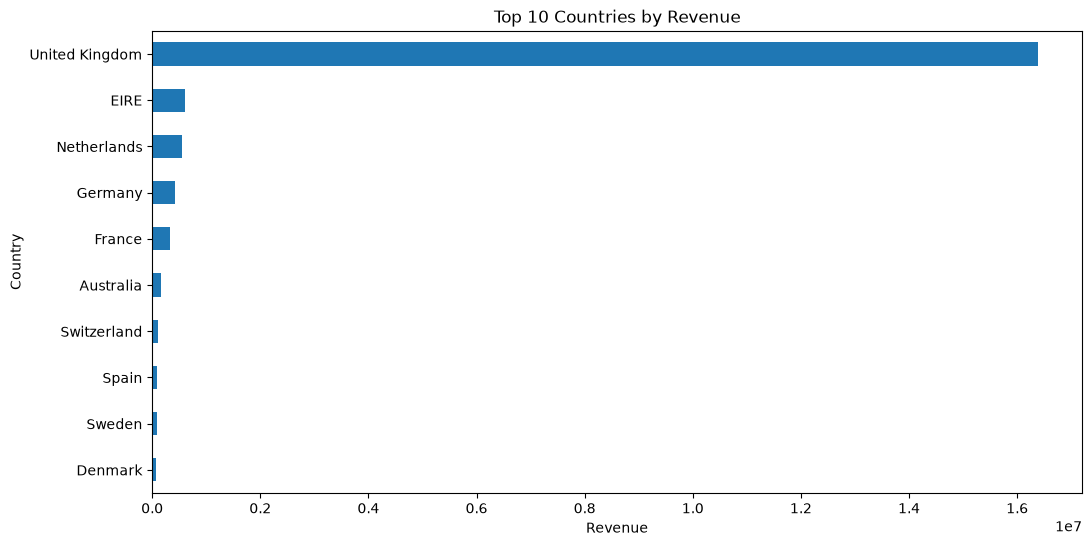

In [28]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

country_sales.head(10).sort_values().plot(kind="barh")

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Country")
plt.tight_layout
plt.show()

#Plotting revenue for trend,spikes,unusual periods,seasonality,gaps

In [29]:
daily_sales = (df.set_index("InvoiceDate").resample("D")["revenue"].sum())

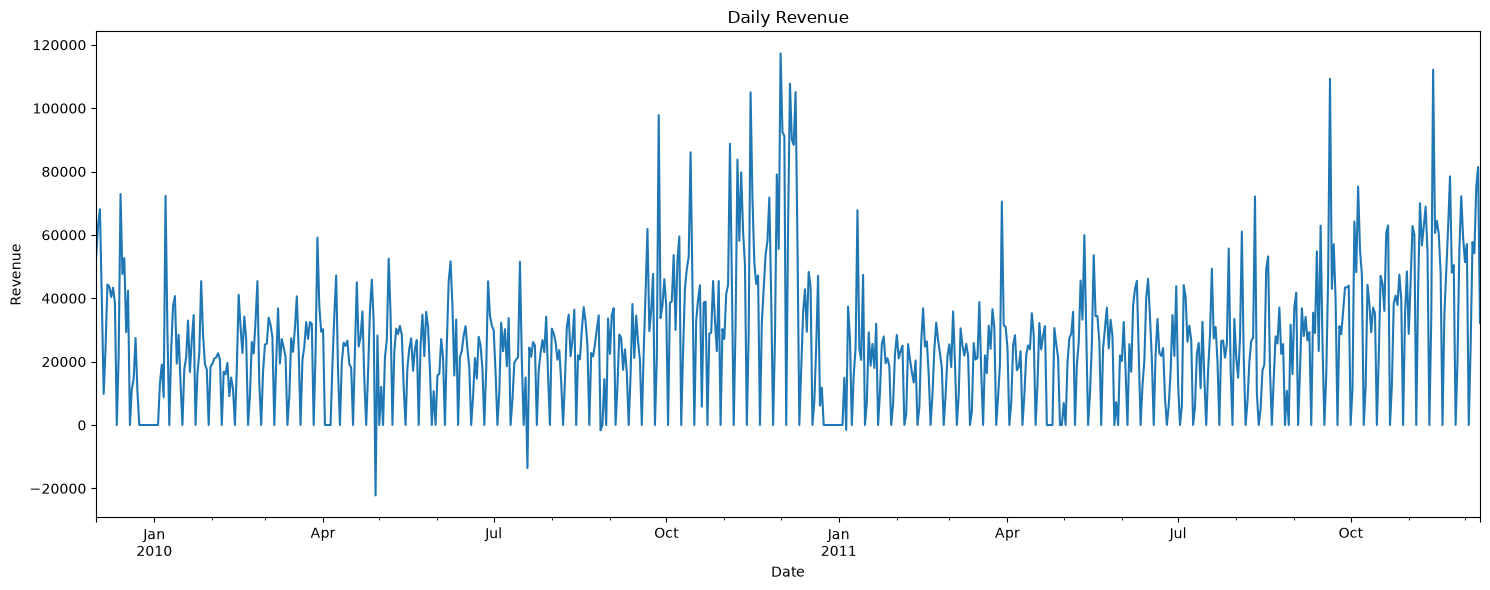

In [30]:
plt.figure(figsize=(15, 6))

daily_sales.plot()

plt.title("Daily Revenue")
plt.xlabel("Date")
plt.ylabel("Revenue")

plt.tight_layout()
plt.show()

#Monthlly revenue

In [31]:
monthly_sales = (df.set_index("InvoiceDate").resample("ME")["revenue"].sum())

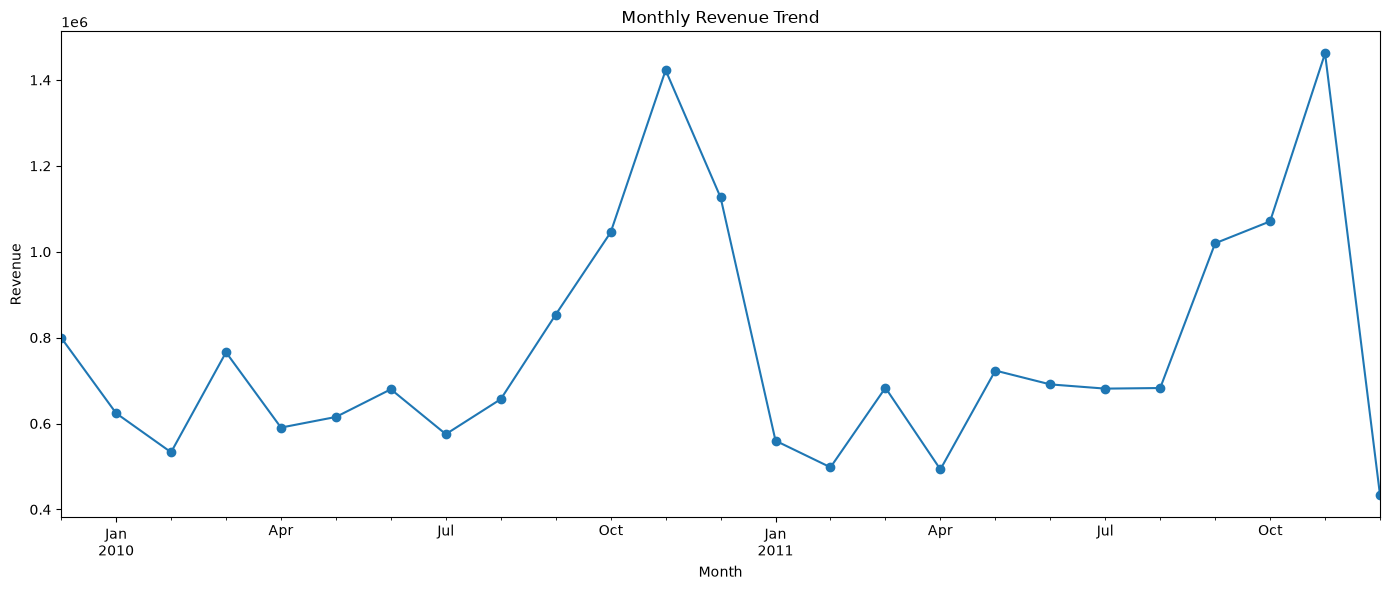

In [32]:
plt.figure(figsize=(14, 6))

monthly_sales.plot(marker="o")

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")

plt.tight_layout()
plt.show()

#Quantity Distribution

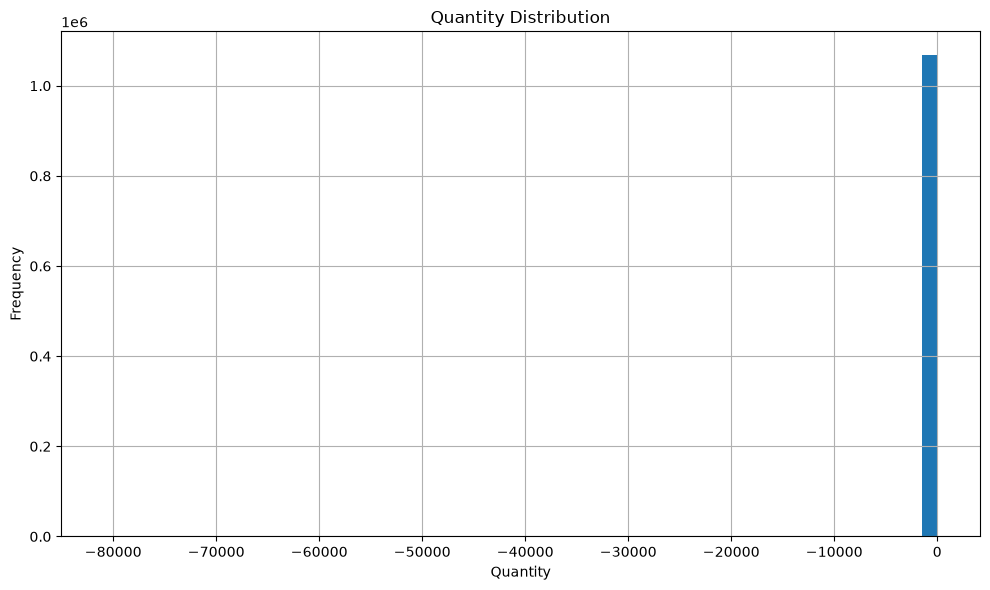

In [33]:
plt.figure(figsize=(10, 6))

df["Quantity"].clip(
    upper=df["Quantity"].quantile(0.99)
).hist(bins=50)

plt.title("Quantity Distribution")
plt.xlabel("Quantity")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

#Price Distribution

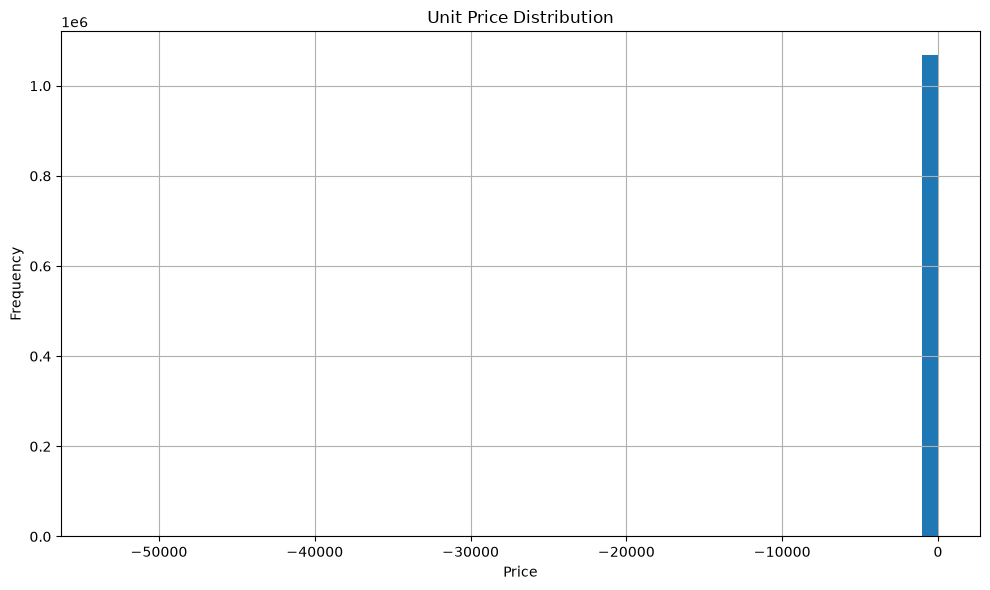

In [34]:
plt.figure(figsize=(10, 6))

df["Price"].clip(
    upper=df["Price"].quantile(0.99)
).hist(bins=50)

plt.title("Unit Price Distribution")
plt.xlabel("Price")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

In [35]:
numeric_columns = [
    "Quantity",
    "Price",
    "revenue"
]

correlation = df[numeric_columns].corr()

correlation

,Quantity,Price,revenue
Quantity,1.000000,-0.001319,0.762623
Price,-0.001319,1.000000,0.061029
revenue,0.762623,0.061029,1.000000


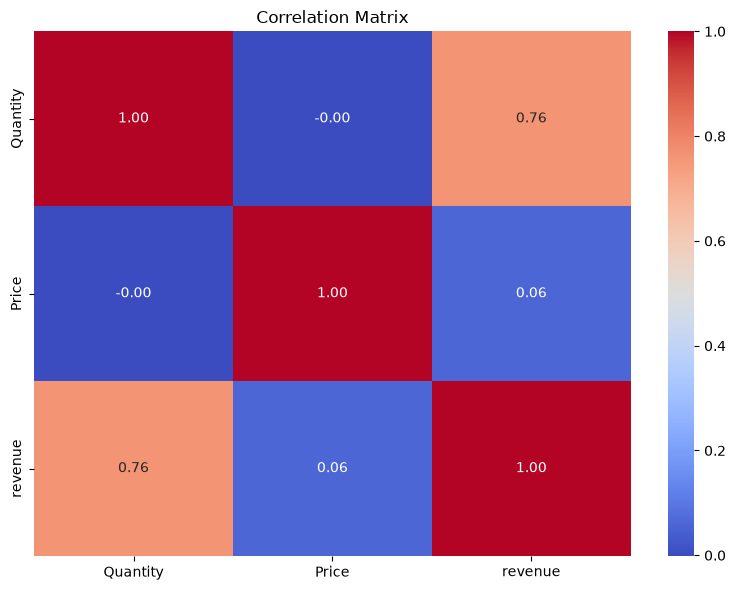

In [36]:
import seaborn as sns

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix")

plt.tight_layout()
plt.show()

#Extreme quantity records

In [37]:
display(df.nlargest(20,"Quantity")[["Invoice","StockCode","Description","Quantity","InvoiceDate","Price","Customer ID","Country"]])

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
1065882,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,16446.0,United Kingdom
587080,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,1.04,12346.0,United Kingdom
90857,497946,37410,BLACK AND WHITE PAISLEY FLOWER MUG,19152,2010-02-15 11:57:00,0.10,13902.0,Denmark
127166,501534,21099,SET/6 STRAWBERRY PAPER CUPS,12960,2010-03-17 13:09:00,0.10,13902.0,Denmark
127168,501534,21091,SET/6 WOODLAND PAPER PLATES,12960,2010-03-17 13:09:00,0.10,13902.0,Denmark
127169,501534,21085,SET/6 WOODLAND PAPER CUPS,12744,2010-03-17 13:09:00,0.10,13902.0,Denmark
1027583,578841,84826,ASSTD DESIGN 3D PAPER STICKERS,12540,2011-11-25 15:57:00,0.00,13256.0,United Kingdom
127167,501534,21092,SET/6 STRAWBERRY PAPER PLATES,12480,2010-03-17 13:09:00,0.10,13902.0,Denmark
192197,507637,84016,FLAG OF ST GEORGE CAR FLAG,10200,2010-05-10 14:55:00,0.00,NaN,United Kingdom
135027,502269,21984,PACK OF 12 PINK PAISLEY TISSUES,10000,2010-03-23 15:36:00,0.25,17940.0,United Kingdom


In [38]:
display(df.nsmallest(20,"Quantity")[["Invoice","StockCode","Description","Quantity","InvoiceDate","Price","Customer ID","Country"]])

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
1065883,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2011-12-09 09:27:00,2.08,16446.0,United Kingdom
587085,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,2011-01-18 10:17:00,1.04,12346.0,United Kingdom
303996,519017,22759,NaN,-9600,2010-08-13 09:14:00,0.00,NaN,United Kingdom
750990,556690,23005,printing smudges/thrown away,-9600,2011-06-14 10:37:00,0.00,NaN,United Kingdom
750991,556691,23005,printing smudges/thrown away,-9600,2011-06-14 10:37:00,0.00,NaN,United Kingdom
507225,C536757,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,-9360,2010-12-02 14:23:00,0.03,15838.0,United Kingdom
529729,C536757,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,-9360,2010-12-02 14:23:00,0.03,15838.0,United Kingdom
156488,504311,22197,NaN,-9200,2010-04-12 14:39:00,0.00,NaN,United Kingdom
750989,556687,23003,Printing smudges/thrown away,-9058,2011-06-14 10:36:00,0.00,NaN,United Kingdom
194372,507913,10120,Zebra invcing error,-9000,2010-05-11 17:16:00,0.00,NaN,United Kingdom


In [39]:
display(df.nlargest(20, "Price"))

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,is_cancelled,revenue
748142,C556445,M,Manual,-1,2011-06-10 15:31:00,38970.00,15098.0,United Kingdom,True,-38970.00
241824,C512770,M,Manual,-1,2010-06-17 16:52:00,25111.09,17399.0,United Kingdom,True,-25111.09
241827,512771,M,Manual,1,2010-06-17 16:53:00,25111.09,NaN,United Kingdom,False,25111.09
320581,C520667,BANK CHARGES,Bank Charges,-1,2010-08-27 13:42:00,18910.69,NaN,United Kingdom,True,-18910.69
1050063,C580605,AMAZONFEE,AMAZON FEE,-1,2011-12-05 11:36:00,17836.46,NaN,United Kingdom,True,-17836.46
569163,C540117,AMAZONFEE,AMAZON FEE,-1,2011-01-05 09:55:00,16888.02,NaN,United Kingdom,True,-16888.02
569164,C540118,AMAZONFEE,AMAZON FEE,-1,2011-01-05 09:57:00,16453.71,NaN,United Kingdom,True,-16453.71
517953,C537630,AMAZONFEE,AMAZON FEE,-1,2010-12-07 15:04:00,13541.33,NaN,United Kingdom,True,-13541.33
517955,537632,AMAZONFEE,AMAZON FEE,1,2010-12-07 15:08:00,13541.33,NaN,United Kingdom,False,13541.33
519294,C537651,AMAZONFEE,AMAZON FEE,-1,2010-12-07 15:49:00,13541.33,NaN,United Kingdom,True,-13541.33


In [40]:
display(df.nsmallest(20, "Price"))

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,is_cancelled,revenue
179403,A506401,B,Adjust bad debt,1,2010-04-29 13:36:00,-53594.36,NaN,United Kingdom,False,-53594.36
276274,A516228,B,Adjust bad debt,1,2010-07-19 11:24:00,-44031.79,NaN,United Kingdom,False,-44031.79
403472,A528059,B,Adjust bad debt,1,2010-10-20 12:04:00,-38925.87,NaN,United Kingdom,False,-38925.87
825444,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom,False,-11062.06
825445,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom,False,-11062.06
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.00,NaN,United Kingdom,False,-0.00
283,489463,71477,short,-240,2009-12-01 10:52:00,0.00,NaN,United Kingdom,False,-0.00
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.00,NaN,United Kingdom,False,-0.00
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.00,NaN,United Kingdom,False,-0.00
3114,489655,20683,NaN,-44,2009-12-01 17:26:00,0.00,NaN,United Kingdom,False,-0.00


In [41]:
customer_orders = (df.dropna(subset=["Customer ID"]).groupby("Customer ID")["Invoice"].nunique())

customer_orders.describe()

count    5942.000000
mean        7.552339
std        15.972262
min         1.000000
25%         2.000000
50%         4.000000
75%         8.000000
max       510.000000
Name: Invoice, dtype: float64

In [42]:
df = df.rename(columns={
    "Invoice": "invoice",
    "StockCode": "stock_code",
    "Description": "description",
    "Quantity": "quantity",
    "InvoiceDate": "invoice_date",
    "Price": "unit_price",
    "Customer ID": "customer_id",
    "Country": "country"
})

In [43]:
df["is_cancelled"] = (df["invoice"].astype(str).str.startswith("C"))

In [44]:
df["revenue"] = (df["quantity"] * df["unit_price"])

In [45]:
df.head()

,invoice,stock_code,description,quantity,invoice_date,unit_price,customer_id,country,is_cancelled,revenue
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,False,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,False,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,False,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,False,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,False,30.0


In [46]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 10 columns):
 #   Column        Non-Null Count    Dtype         
---  ------        --------------    -----         
 0   invoice       1067371 non-null  object        
 1   stock_code    1067371 non-null  object        
 2   description   1062989 non-null  object        
 3   quantity      1067371 non-null  int64         
 4   invoice_date  1067371 non-null  datetime64[us]
 5   unit_price    1067371 non-null  float64       
 6   customer_id   824364 non-null   float64       
 7   country       1067371 non-null  str           
 8   is_cancelled  1067371 non-null  bool          
 9   revenue       1067371 non-null  float64       
dtypes: bool(1), datetime64[us](1), float64(3), int64(1), object(3), str(1)
memory usage: 88.0+ MB


In [47]:
df["customer_id"] = df["customer_id"].astype("Int64")
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 10 columns):
 #   Column        Non-Null Count    Dtype         
---  ------        --------------    -----         
 0   invoice       1067371 non-null  object        
 1   stock_code    1067371 non-null  object        
 2   description   1062989 non-null  object        
 3   quantity      1067371 non-null  int64         
 4   invoice_date  1067371 non-null  datetime64[us]
 5   unit_price    1067371 non-null  float64       
 6   customer_id   824364 non-null   Int64         
 7   country       1067371 non-null  str           
 8   is_cancelled  1067371 non-null  bool          
 9   revenue       1067371 non-null  float64       
dtypes: Int64(1), bool(1), datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 89.0+ MB


In [48]:
pd.crosstab(
    df["is_cancelled"],
    df["quantity"] < 0,
    margins=True
)

quantity,False,True,All
is_cancelled,,,
False,1044420,3457,1047877
True,1,19493,19494
All,1044421,22950,1067371


In [49]:
cancelled_df = df[df["is_cancelled"]].copy()

cancelled_df[
    [
        "invoice",
        "stock_code",
        "description",
        "quantity",
        "invoice_date",
        "unit_price",
        "customer_id",
        "country",
        "revenue"
    ]
].head(20)

cancelled_df["quantity"].describe()

count    19494.000000
mean       -25.186827
std        805.104908
min     -80995.000000
25%         -6.000000
50%         -2.000000
75%         -1.000000
max          1.000000
Name: quantity, dtype: float64

In [50]:
print(cancelled_df["revenue"].describe())


count     19494.000000
mean        -78.314756
std        1459.635817
min     -168469.600000
25%         -17.850000
50%          -8.950000
75%          -3.750000
max         373.570000
Name: revenue, dtype: float64


In [51]:
negative_non_cancelled = df[
    (~df["is_cancelled"]) &
    (df["quantity"] < 0)
]

print(
    "Negative quantity without cancellation:",
    len(negative_non_cancelled)
)

Negative quantity without cancellation: 3457


In [52]:
negative_non_cancelled.head(10)

,invoice,stock_code,description,quantity,invoice_date,unit_price,customer_id,country,is_cancelled,revenue
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.0,<NA>,United Kingdom,False,-0.0
283,489463,71477,short,-240,2009-12-01 10:52:00,0.0,<NA>,United Kingdom,False,-0.0
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.0,<NA>,United Kingdom,False,-0.0
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.0,<NA>,United Kingdom,False,-0.0
3114,489655,20683,NaN,-44,2009-12-01 17:26:00,0.0,<NA>,United Kingdom,False,-0.0
3162,489660,35956,lost,-1043,2009-12-01 17:43:00,0.0,<NA>,United Kingdom,False,-0.0
3168,489663,35605A,damages,-117,2009-12-01 18:02:00,0.0,<NA>,United Kingdom,False,-0.0
4296,489806,18010,NaN,-770,2009-12-02 12:42:00,0.0,<NA>,United Kingdom,False,-0.0
4538,489820,21133,invcd as 84879?,-720,2009-12-02 13:23:00,0.0,<NA>,United Kingdom,False,-0.0
4566,489821,85049G,NaN,-240,2009-12-02 13:25:00,0.0,<NA>,United Kingdom,False,-0.0


In [53]:
pd.crosstab(
    df["is_cancelled"],
    df["quantity"] < 0,
    margins=True
)

quantity,False,True,All
is_cancelled,,,
False,1044420,3457,1047877
True,1,19493,19494
All,1044421,22950,1067371


In [54]:
negative_non_cancelled = df[(~df["is_cancelled"]) &(df["quantity"] < 0)].copy()

negative_non_cancelled[
    [
        "invoice",
        "stock_code",
        "description",
        "quantity",
        "invoice_date",
        "unit_price",
        "customer_id",
        "country",
        "revenue"
    ]
].head()

,invoice,stock_code,description,quantity,invoice_date,unit_price,customer_id,country,revenue
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.0,<NA>,United Kingdom,-0.0
283,489463,71477,short,-240,2009-12-01 10:52:00,0.0,<NA>,United Kingdom,-0.0
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.0,<NA>,United Kingdom,-0.0
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.0,<NA>,United Kingdom,-0.0
3114,489655,20683,NaN,-44,2009-12-01 17:26:00,0.0,<NA>,United Kingdom,-0.0


In [55]:
cancelled_positive = df[(df["is_cancelled"]) &(df["quantity"] > 0)]

display(cancelled_positive)

,invoice,stock_code,description,quantity,invoice_date,unit_price,customer_id,country,is_cancelled,revenue
76799,C496350,M,Manual,1,2010-02-01 08:24:00,373.57,<NA>,United Kingdom,True,373.57


In [56]:
display(
    df.nsmallest(
        10,
        "quantity"
    )[
        [
            "invoice",
            "stock_code",
            "description",
            "quantity",
            "invoice_date",
            "unit_price",
            "customer_id",
            "country",
            "revenue",
            "is_cancelled"
        ]
    ]
)

,invoice,stock_code,description,quantity,invoice_date,unit_price,customer_id,country,revenue,is_cancelled
1065883,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2011-12-09 09:27:00,2.08,16446,United Kingdom,-168469.6,True
587085,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,2011-01-18 10:17:00,1.04,12346,United Kingdom,-77183.6,True
303996,519017,22759,NaN,-9600,2010-08-13 09:14:00,0.00,<NA>,United Kingdom,-0.0,False
750990,556690,23005,printing smudges/thrown away,-9600,2011-06-14 10:37:00,0.00,<NA>,United Kingdom,-0.0,False
750991,556691,23005,printing smudges/thrown away,-9600,2011-06-14 10:37:00,0.00,<NA>,United Kingdom,-0.0,False
507225,C536757,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,-9360,2010-12-02 14:23:00,0.03,15838,United Kingdom,-280.8,True
529729,C536757,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,-9360,2010-12-02 14:23:00,0.03,15838,United Kingdom,-280.8,True
156488,504311,22197,NaN,-9200,2010-04-12 14:39:00,0.00,<NA>,United Kingdom,-0.0,False
750989,556687,23003,Printing smudges/thrown away,-9058,2011-06-14 10:36:00,0.00,<NA>,United Kingdom,-0.0,False
194372,507913,10120,Zebra invcing error,-9000,2010-05-11 17:16:00,0.00,<NA>,United Kingdom,-0.0,False


In [57]:
negative_non_cancelled["quantity"].describe()


count    3457.000000
mean     -165.775239
std       673.108503
min     -9600.000000
25%       -82.000000
50%       -26.000000
75%        -8.000000
max        -1.000000
Name: quantity, dtype: float64

In [58]:
negative_non_cancelled["revenue"].describe()

count    3457.0
mean        0.0
std         0.0
min        -0.0
25%         0.0
50%         0.0
75%         0.0
max        -0.0
Name: revenue, dtype: float64

In [59]:
sales_df = df[(~df["is_cancelled"]) & (df["quantity"] > 0) & (df["unit_price"] > 0)].copy()

In [60]:
returns_df = df[df["quantity"] < 0].copy()

In [61]:
cancelled_df = df[df["is_cancelled"]].copy()

In [62]:
print("Master dataset:", len(df))
print("Sales dataset:", len(sales_df))
print("Returns dataset:", len(returns_df))
print("Cancelled dataset:", len(cancelled_df))

Master dataset: 1067371
Sales dataset: 1041670
Returns dataset: 22950
Cancelled dataset: 19494


In [63]:
print("Negative quantities in sales:",(sales_df["quantity"] < 0).sum())

print("Zero/negative prices in sales:", (sales_df["unit_price"] <= 0).sum())

print("Cancelled invoices in sales:", sales_df["is_cancelled"].sum())

Negative quantities in sales: 0
Zero/negative prices in sales: 0
Cancelled invoices in sales: 0


#Duplicate Analysis

In [64]:
duplicate_rows = df[df.duplicated(keep=False)].copy()

print("Duplicate rows:", len(duplicate_rows))
print("Percentage:", len(duplicate_rows) / len(df) * 100)

Duplicate rows: 67242
Percentage: 6.299777678051961


In [65]:
display(duplicate_rows.sort_values(["invoice", "stock_code","invoice_date"]).head(30))

,invoice,stock_code,description,quantity,invoice_date,unit_price,customer_id,country,is_cancelled,revenue
379,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329,United Kingdom,False,1.95
391,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329,United Kingdom,False,1.95
365,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329,United Kingdom,False,3.75
386,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329,United Kingdom,False,3.75
363,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329,United Kingdom,False,3.75
371,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329,United Kingdom,False,3.75
394,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329,United Kingdom,False,3.75
362,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329,United Kingdom,False,3.75
385,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329,United Kingdom,False,3.75
368,489517,22130,PARTY CONE CHRISTMAS DECORATION,6,2009-12-01 11:34:00,0.85,16329,United Kingdom,False,5.10


In [66]:
print("Duplicate rows in sales_df:",sales_df.duplicated().sum())

Duplicate rows in sales_df: 33757


In [67]:
print("Exact duplicate rows to remove:",df.duplicated().sum())

print("Percentage:",df.duplicated().mean() * 100)

Exact duplicate rows to remove: 34335
Percentage: 3.2167821685243467


In [68]:
print("Exact duplicate rows in sales_df:",sales_df.duplicated().sum())

print("Percentage:", sales_df.duplicated().mean() * 100)

Exact duplicate rows in sales_df: 33757
Percentage: 3.2406616298827844


#This tells us whether there are cases where the same product appears multiple times on an invoice.

In [69]:
invoice_product_counts = (df.groupby(["invoice", "stock_code"]).size().sort_values(ascending=False))

print(invoice_product_counts.head(20))

invoice  stock_code
555524   22698         20
C544580  S             16
555524   22697         12
536412   21448         10
537224   70007         10
C514024  M             10
537646   22585         10
502660   17021          9
537202   22147          8
572861   22775          8
536464   22866          8
537154   22727          8
578289   23395          7
C528093  S              7
536162   M              7
572344   M              7
C553531  S              7
C544583  S              7
C506607  S              7
538514   21756          6
dtype: int64


In [70]:
repeated_invoice_products = (df.groupby(["invoice", "stock_code"]).size())

repeated_invoice_products = repeated_invoice_products[repeated_invoice_products > 1]

print("Invoice-product combinations appearing more than once:", len(repeated_invoice_products))

Invoice-product combinations appearing more than once: 42638


In [71]:
df.duplicated().sum()

np.int64(34335)

In [72]:
rows_before = len(df)
print("Rows before removal of duplicates:", rows_before)

Rows before removal of duplicates: 1067371


#Removing the exact duplicates 

In [73]:
df = df.drop_duplicates().copy()

In [74]:
rows_after = len(df)

print("Rows after deduplication:", rows_after)
print("Rows removed:", rows_before - rows_after)
print("Percentage removed:",(rows_before - rows_after) / rows_before * 100)

Rows after deduplication: 1033036
Rows removed: 34335
Percentage removed: 3.2167821685243467


In [75]:
sales_df = df[(~df["is_cancelled"]) &(df["quantity"] > 0) &(df["unit_price"] > 0)].copy()

In [76]:
returns_df = df[df["quantity"] < 0].copy()

In [77]:
cancelled_df = df[df["is_cancelled"]].copy()

In [78]:
print("Clean master dataset:", len(df))
print("Sales dataset:", len(sales_df))
print("Returns dataset:", len(returns_df))
print("Cancelled dataset:", len(cancelled_df))

Clean master dataset: 1033036
Sales dataset: 1007913
Returns dataset: 22496
Cancelled dataset: 19104


In [79]:
print("Duplicate rows in master:",df.duplicated().sum())

print("Duplicate rows in sales:",sales_df.duplicated().sum())

print("Negative quantities in sales:",(sales_df["quantity"] < 0).sum())

print("Zero/negative prices in sales:",(sales_df["unit_price"] <= 0).sum())

print("Cancelled invoices in sales:", sales_df["is_cancelled"].sum())

Duplicate rows in master: 0
Duplicate rows in sales: 0
Negative quantities in sales: 0
Zero/negative prices in sales: 0
Cancelled invoices in sales: 0


#Missing value analysis

In [ ]:
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percentage": (
        df.isna().mean() * 100
    )
})

missing_summary = missing_summary.sort_values("missing_count",ascending=False)

display(missing_summary)

,missing_count,missing_percentage
customer_id,235151,22.763098
description,4275,0.413829
stock_code,0,0.000000
invoice,0,0.000000
invoice_date,0,0.000000
quantity,0,0.000000
unit_price,0,0.000000
country,0,0.000000
is_cancelled,0,0.000000
revenue,0,0.000000


In [81]:
missing_customer = df[df["customer_id"].isna()].copy()

print("Missing customer ID:", len(missing_customer))

Missing customer ID: 235151


In [82]:
display(
    missing_customer[
        [
            "invoice",
            "stock_code",
            "description",
            "quantity",
            "invoice_date",
            "unit_price",
            "country",
            "revenue",
            "is_cancelled"
        ]
    ].head(20)
)

,invoice,stock_code,description,quantity,invoice_date,unit_price,country,revenue,is_cancelled
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.00,United Kingdom,-0.00,False
283,489463,71477,short,-240,2009-12-01 10:52:00,0.00,United Kingdom,-0.00,False
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.00,United Kingdom,-0.00,False
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.00,United Kingdom,-0.00,False
577,489525,85226C,BLUE PULL BACK RACING CAR,1,2009-12-01 11:49:00,0.55,United Kingdom,0.55,False
578,489525,85227,SET/6 3D KIT CARDS FOR KIDS,1,2009-12-01 11:49:00,0.85,United Kingdom,0.85,False
1055,489548,22271,FELTCRAFT DOLL ROSIE,1,2009-12-01 12:32:00,2.95,United Kingdom,2.95,False
1056,489548,22254,FELT TOADSTOOL LARGE,12,2009-12-01 12:32:00,1.25,United Kingdom,15.00,False
1057,489548,22273,FELTCRAFT DOLL MOLLY,3,2009-12-01 12:32:00,2.95,United Kingdom,8.85,False
1058,489548,22195,LARGE HEART MEASURING SPOONS,1,2009-12-01 12:32:00,1.65,United Kingdom,1.65,False


#Missing customer IDs by dataset

In [83]:
print("Sales without customer ID:",sales_df["customer_id"].isna().sum())

print("Returns without customer ID:",returns_df["customer_id"].isna().sum())

print("Cancellations without customer ID:",cancelled_df["customer_id"].isna().sum())

Sales without customer ID: 228488
Returns without customer ID: 4106
Cancellations without customer ID: 714


In [84]:
missing_description = df[df["description"].isna()].copy()

print("Missing descriptions:", len(missing_description))

Missing descriptions: 4275


In [85]:
display(
    missing_description[
        [
            "invoice",
            "stock_code",
            "quantity",
            "invoice_date",
            "unit_price",
            "customer_id",
            "country"
        ]
    ].head(20)
)

,invoice,stock_code,quantity,invoice_date,unit_price,customer_id,country
470,489521,21646,-50,2009-12-01 11:44:00,0.0,<NA>,United Kingdom
3114,489655,20683,-44,2009-12-01 17:26:00,0.0,<NA>,United Kingdom
3161,489659,21350,230,2009-12-01 17:39:00,0.0,<NA>,United Kingdom
3731,489781,84292,17,2009-12-02 11:45:00,0.0,<NA>,United Kingdom
4296,489806,18010,-770,2009-12-02 12:42:00,0.0,<NA>,United Kingdom
4566,489821,85049G,-240,2009-12-02 13:25:00,0.0,<NA>,United Kingdom
6378,489882,35751C,12,2009-12-02 16:22:00,0.0,<NA>,United Kingdom
6555,489898,79323G,954,2009-12-03 09:40:00,0.0,<NA>,United Kingdom
6576,489901,21098,-200,2009-12-03 09:47:00,0.0,<NA>,United Kingdom
6581,489903,21166,48,2009-12-03 09:57:00,0.0,<NA>,United Kingdom


#checking whether each stock_code consistently maps to one description.

In [86]:
description_mapping = (
    df.dropna(subset=["description"])
      .groupby("stock_code")["description"]
      .nunique()
      .sort_values(ascending=False)
)

print("Stock codes with multiple descriptions:", (description_mapping > 1).sum())

print("Unique stock codes:", description_mapping.shape[0])

Stock codes with multiple descriptions: 1232
Unique stock codes: 4950


finding the missing-description records whose stock code has a known description

In [ ]:
known_stock_codes = set(df.loc[df["description"].notna(),"stock_code"])

recoverable = missing_description[missing_description["stock_code"].isin(known_stock_codes)]

print("Potentially recoverable descriptions:", len(recoverable))

Potentially recoverable descriptions: 3912


In [ ]:
description_variants = (df.dropna(subset=["description"]).groupby("stock_code")["description"].unique())

multi_description = description_variants[description_variants.apply(len) > 1]

print("Stock codes with multiple descriptions:",len(multi_description))

display(multi_description.head(20))

Stock codes with multiple descriptions: 1232


stock_code
10080                    [GROOVY CACTUS INFLATABLE, check]
10120                  [DOGGY RUBBER, Zebra invcing error]
10133              [COLOURING PENCILS BROWN TUBE, damaged]
16008         [SMALL FOLDING SCISSOR(POINTED EDGE), check]
16011                  [ ANIMAL STICKERS, ANIMAL STICKERS]
16012    [FOOD/DRINK SPUNGE STICKERS, FOOD/DRINK SPONGE...
16045                  [POPART WOODEN PENCILS ASST, check]
16235              [RECYCLED PENCIL WITH RABBIT ERASER, ?]
17033    [BROCADE PURSE,SMALL ARCH BUTTON, sold as 1700...
20615    [BLUE SPOTTY PASSPORT COVER, BLUE POLKADOT PAS...
20622            [VIPPASSPORT COVER , VIP PASSPORT COVER ]
20652    [BLUE SPOTTY LUGGAGE TAG , BLUE POLKADOT LUGGA...
20658    [RED SPOTTY LUGGAGE TAG, RED RETROSPOT LUGGAGE...
20661           [BLUE SPOTTY PURSE , BLUE POLKADOT PURSE ]
20665    [RED SPOTTY PURSE , RED RETROSPOT PURSE , dotc...
20674             [GREEN SPOTTY BOWL, GREEN POLKADOT BOWL]
20675               [BLUE SPOTTY BOWL, BLUE P

In [89]:
df["description_normalized"] = (
    df["description"]
      .astype("string")
      .str.strip()
      .str.upper()
      .str.replace(r"\s+", " ", regex=True)
)

In [ ]:
normalized_variants = (df.dropna(subset=["description_normalized"]).groupby("stock_code")["description_normalized"].nunique())

print("Stock codes with multiple descriptions after normalization:",(normalized_variants > 1).sum())

Stock codes with multiple descriptions after normalization: 1210


In [91]:
display(multi_description.head(20))

stock_code
10080                    [GROOVY CACTUS INFLATABLE, check]
10120                  [DOGGY RUBBER, Zebra invcing error]
10133              [COLOURING PENCILS BROWN TUBE, damaged]
16008         [SMALL FOLDING SCISSOR(POINTED EDGE), check]
16011                  [ ANIMAL STICKERS, ANIMAL STICKERS]
16012    [FOOD/DRINK SPUNGE STICKERS, FOOD/DRINK SPONGE...
16045                  [POPART WOODEN PENCILS ASST, check]
16235              [RECYCLED PENCIL WITH RABBIT ERASER, ?]
17033    [BROCADE PURSE,SMALL ARCH BUTTON, sold as 1700...
20615    [BLUE SPOTTY PASSPORT COVER, BLUE POLKADOT PAS...
20622            [VIPPASSPORT COVER , VIP PASSPORT COVER ]
20652    [BLUE SPOTTY LUGGAGE TAG , BLUE POLKADOT LUGGA...
20658    [RED SPOTTY LUGGAGE TAG, RED RETROSPOT LUGGAGE...
20661           [BLUE SPOTTY PURSE , BLUE POLKADOT PURSE ]
20665    [RED SPOTTY PURSE , RED RETROSPOT PURSE , dotc...
20674             [GREEN SPOTTY BOWL, GREEN POLKADOT BOWL]
20675               [BLUE SPOTTY BOWL, BLUE P

In [ ]:
description_counts = (df.dropna(subset=["description_normalized"]).groupby("stock_code")["description_normalized"].nunique())

unambiguous_stock_codes = description_counts[description_counts == 1].index

print("Stock codes with exactly one normalized description:", len(unambiguous_stock_codes))

Stock codes with exactly one normalized description: 3740


#Finding the stock codes where the description is unambiguous

In [93]:
recoverable_unambiguous = df[df["description"].isna() & df["stock_code"].isin(unambiguous_stock_codes)]

print("Missing descriptions safely recoverable:", len(recoverable_unambiguous))

Missing descriptions safely recoverable: 2984


In [94]:
description_map = (df.dropna(subset=["description_normalized"]).groupby("stock_code")["description_normalized"].first())

In [95]:
df["description_clean"] = df["description"]

mask = (df["description_clean"].isna() & df["stock_code"].isin(unambiguous_stock_codes))

df.loc[mask, "description_clean"] = (df.loc[mask, "stock_code"].map(description_map))

In [96]:
print("Missing descriptions before:",df["description"].isna().sum())

print("Missing descriptions after:", df["description_clean"].isna().sum())

print("Descriptions recovered:",(df["description"].isna() & df["description_clean"].notna()).sum())

Missing descriptions before: 4275
Missing descriptions after: 1291
Descriptions recovered: 2984


In [97]:
if "description_normalized" in df.columns: df.drop(columns=["description_normalized"], inplace=True)

In [98]:
df.info()

<class 'pandas.DataFrame'>
Index: 1033036 entries, 0 to 1067370
Data columns (total 11 columns):
 #   Column             Non-Null Count    Dtype         
---  ------             --------------    -----         
 0   invoice            1033036 non-null  object        
 1   stock_code         1033036 non-null  object        
 2   description        1028761 non-null  object        
 3   quantity           1033036 non-null  int64         
 4   invoice_date       1033036 non-null  datetime64[us]
 5   unit_price         1033036 non-null  float64       
 6   customer_id        797885 non-null   Int64         
 7   country            1033036 non-null  str           
 8   is_cancelled       1033036 non-null  bool          
 9   revenue            1033036 non-null  float64       
 10  description_clean  1031745 non-null  object        
dtypes: Int64(1), bool(1), datetime64[us](1), float64(2), int64(1), object(4), str(1)
memory usage: 102.0+ MB


In [99]:
print("Latest sales date:", sales_df["invoice_date"].max())

reference_date = sales_df["invoice_date"].max() + pd.Timedelta(days=1)

print("RFM reference date:", reference_date)

Latest sales date: 2011-12-09 12:50:00
RFM reference date: 2011-12-10 12:50:00


In [100]:
rfm_sales = sales_df[sales_df["customer_id"].notna()].copy()

print("Sales transactions:", len(sales_df))
print("Transactions with customer ID:", len(rfm_sales))
print("Unique customers:", rfm_sales["customer_id"].nunique())

Sales transactions: 1007913
Transactions with customer ID: 779425
Unique customers: 5878


In [101]:
print("Master dataset shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nDuplicate rows:", df.duplicated().sum())

Master dataset shape: (1033036, 11)

Columns:
['invoice', 'stock_code', 'description', 'quantity', 'invoice_date', 'unit_price', 'customer_id', 'country', 'is_cancelled', 'revenue', 'description_clean']

Duplicate rows: 0


In [102]:
from pathlib import Path

processed_dir = Path("../data/processed")
processed_dir.mkdir(parents=True, exist_ok=True)

print("Processed data directory:", processed_dir.resolve())

Processed data directory: E:\RetailPulse\data\processed


In [103]:
import pandas as pd
import pyarrow as pa

print(pd.__version__)
print(pa.__version__)

3.0.6
25.0.1


In [105]:
df.dtypes

invoice                      object
stock_code                   object
description                  object
quantity                      int64
invoice_date         datetime64[us]
unit_price                  float64
customer_id                   Int64
country                         str
is_cancelled                   bool
revenue                     float64
description_clean            object
dtype: object

In [106]:
for col in df.columns:
    try:
        df[[col]].to_parquet(
            processed_dir / f"_test_{col}.parquet",
            engine="pyarrow",
            index=False
        )
        print(f"✓ {col}")
    except Exception as e:
        print(f"✗ {col}: {type(e).__name__}: {e}")

✗ invoice: ArrowInvalid: ("Could not convert 'C489449' with type str: tried to convert to int64", 'Conversion failed for column invoice with type object')
✗ stock_code: ArrowInvalid: ("Could not convert '79323P' with type str: tried to convert to int64", 'Conversion failed for column stock_code with type object')
✗ description: ArrowTypeError: ("Expected bytes, got a 'int' object", 'Conversion failed for column description with type object')
✓ quantity
✓ invoice_date
✓ unit_price
✓ customer_id
✓ country
✓ is_cancelled
✓ revenue
✗ description_clean: ArrowTypeError: ("Expected bytes, got a 'int' object", 'Conversion failed for column description_clean with type object')


In [107]:
# Convert identifier/text columns to consistent string types

df["invoice"] = df["invoice"].astype("string")
df["stock_code"] = df["stock_code"].astype("string")
df["description"] = df["description"].astype("string")
df["description_clean"] = df["description_clean"].astype("string")
df["country"] = df["country"].astype("string")

In [108]:
df.dtypes

invoice                      string
stock_code                   string
description                  string
quantity                      int64
invoice_date         datetime64[us]
unit_price                  float64
customer_id                   Int64
country                      string
is_cancelled                   bool
revenue                     float64
description_clean            string
dtype: object

In [ ]:
clean_transactions_path = (processed_dir / "clean_transactions.parquet")

df.to_parquet(clean_transactions_path, engine="pyarrow",index=False)

print("Saved:", clean_transactions_path)

Saved: ..\data\processed\clean_transactions.parquet


In [ ]:
sales_df = df[
    (~df["is_cancelled"]) &
    (df["quantity"] > 0) &
    (df["unit_price"] > 0)
].copy()

returns_df = df[df["quantity"] < 0].copy()

cancelled_df = df[df["is_cancelled"]].copy()

In [112]:
print("Clean master:", len(df))
print("Sales:", len(sales_df))
print("Returns:", len(returns_df))
print("Cancelled:", len(cancelled_df))

Clean master: 1033036
Sales: 1007913
Returns: 22496
Cancelled: 19104


In [ ]:
sales_path = processed_dir / "clean_sales.parquet"
returns_path = processed_dir / "clean_returns.parquet"
cancelled_path = processed_dir / "clean_cancelled.parquet"

sales_df.to_parquet(sales_path, engine="pyarrow", index=False)

returns_df.to_parquet(returns_path, engine="pyarrow", index=False)

cancelled_df.to_parquet(cancelled_path, engine="pyarrow", index=False)

print("All processed datasets saved successfully.")

All processed datasets saved successfully.
